# Mortgage price elasticity: model explorer

This notebook lets you **try price scenarios** and **see what the model says** in pictures. Every
chart comes from one module, `mortgage_elasticity/visuals.py`, so the same pictures can be produced
without the notebook (`uv run elasticity charts`).

**The question the model answers:** if we change our rate in a segment by some number of basis
points, what happens to our applications and share over the next 12 weeks, and how sure are we?

| Part | What it covers | Needs a fitted model? |
|---|---|---|
| **A. How the model works** | The three ideas behind it: the response curve, the delay, the market benchmark | No (A3 does) |
| **B. What the model learned** | Price sensitivity by segment, and what share would have been without price moves | Yes |
| **C. Scenarios** | Your own price moves and competitor responses, in 1-D, 2-D and 3-D views | Yes |
| **D. How far to trust it** | Raw history, backtests, precision and judgment checks | Yes |
| **E. Save the charts** | Write every chart as a PNG for a pack | Yes |

**How to use it.** Run the cells from the top. Cells headed `# SETTINGS` are the ones to edit;
change a value and rerun that cell and the ones below it in the same section.

**Reading the charts.**

| Term | Meaning |
|---|---|
| **bp** | Basis point, 0.01 of a percentage point. A **negative** price change is a **cut**. |
| **Price gap** | How much dearer we look than the market, against where we started. It moves when we reprice *and* when competitors do. |
| **Uplift per bp** | Price sensitivity: the % rise in our applications from a 1bp cut. |
| **Change in applications** | Always against "no price change" over the same weeks, so +20% means a fifth more than we would otherwise have had. |
| **80% range** | Four times in five the truth should fall inside it, one time in five outside. |
| **Price effect only** | The range if nothing else changes: no competitor response, no market movement. |
| **With drift and noise** | The range to expect in practice, once ordinary market movement and week-to-week chance are added. |

Plain-language description of each step: [`docs/overview.md`](../docs/overview.md). Derivations:
[`docs/model_maths.pdf`](../docs/model_maths.pdf). The **Maths** notes below give the formula
behind each chart and the matching section (§) of both documents.

## Setup

Loads a fitted model (`fit.pkl`, written by `uv run elasticity estimate`). The default is the fit
on the **synthetic sample data**, where the true sensitivities are known. Point `FIT_PATH` at
your own run to use real data, and set `TRUTH_PATH = None`.

In [1]:
# SETTINGS: which fitted model to explore
FIT_PATH = "outputs/sample/fit.pkl"        # written by `uv run elasticity estimate`
TRUTH_PATH = "data/sample/truth.json"      # simulated data only; set to None for real data
SEGMENT = None                             # e.g. "OO_PI_70-80"; None = our largest segment

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from mortgage_elasticity import forecast, report
from mortgage_elasticity import visuals as viz
from mortgage_elasticity.bayes import Fit

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
fit_path = ROOT / FIT_PATH
if not fit_path.exists():
    raise FileNotFoundError(
        f"{fit_path} not found. Fit the model first (about 3 minutes on the sample data):\n"
        "  uv run elasticity simulate\n"
        "  uv run elasticity estimate --panel data/sample/panel.csv --events data/sample/events.csv"
        " --competitors data/sample/competitors.csv --out outputs/sample")
fit = Fit.load(fit_path)
OUT = fit_path.parent                      # the other tables of the same run are read from here
truth = json.loads((ROOT / TRUTH_PATH).read_text()) if TRUTH_PATH else None
SEGMENT = SEGMENT or fit.prep.segs[int(fit.prep.L.mean(0).argmax())]

prep = fit.prep
print(f"{len(prep.segs)} segments x {len(prep.periods)} weeks, "
      f"{prep.periods[0].date()} to {prep.periods[-1].date()}")
print(f"{len(prep.moves('price'))} own price moves, {len(prep.moves('other'))} logged non-price changes")
print(f"Sampler diagnostics: {'reliable' if fit.diag['reliable'] else 'UNRELIABLE RUN, do not use'}")
print(f"Segment used for the single-segment charts: {SEGMENT}")
print("Segments:", ", ".join(prep.segs))

20 segments x 104 weeks, 2024-07-07 to 2026-06-28
12 own price moves, 3 logged non-price changes
Sampler diagnostics: reliable
Segment used for the single-segment charts: OO_PI_<=60
Segments: INV_IO_60-70, INV_IO_70-80, INV_IO_80-90, INV_IO_<=60, INV_IO_>90, INV_PI_60-70, INV_PI_70-80, INV_PI_80-90, INV_PI_<=60, INV_PI_>90, OO_IO_60-70, OO_IO_70-80, OO_IO_80-90, OO_IO_<=60, OO_IO_>90, OO_PI_60-70, OO_PI_70-80, OO_PI_80-90, OO_PI_<=60, OO_PI_>90


---
# Part A. How the model works

Three ideas carry the whole model. These charts use the formulas only, so you can change the
inputs freely to build intuition.

## A1. The response curve: how applications react to price

**What it shows.** The change in applications once a price move is fully felt, at three price
sensitivities. The defaults are the low, middle and high of the range the model starts from.

**How to read it.** Left of zero is a cut, right is a rise. The curves bend: each extra bp of
cut adds a little more than the last, and a rise can never lose more than 100%.

**Business meaning.** Sensitivity is the number everything else hangs on. At 1.2% per bp a 10bp
cut is a modest lift; at 7.4% it roughly doubles volume. The model's job is to say where in that
span each segment sits.

**Maths (§5, §7).** With share $s$ and logit slope $\beta = u/(1-s)$, a change $x$ in the price
gap multiplies applications by $m(x) = 1 / \big(s + (1-s)\,e^{\beta x}\big)$, so
$-\,\mathrm{d}\ln m/\mathrm{d}x\,|_{x=0} = \beta(1-s) = u$.

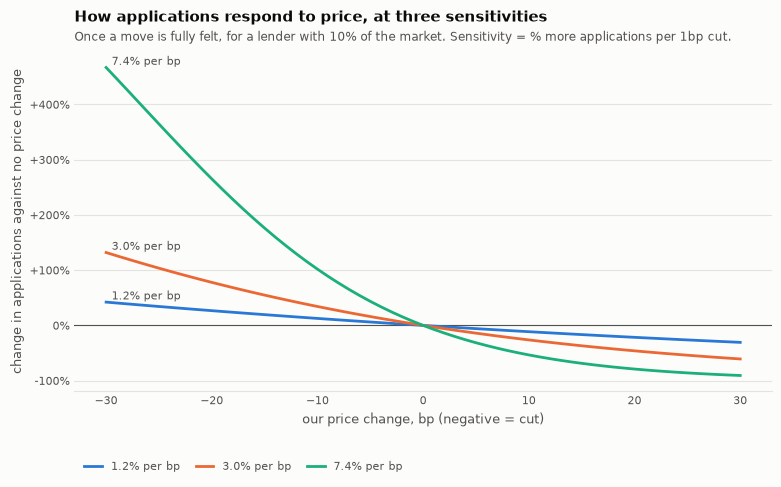

In [ ]:
# SETTINGS
SHARE = 0.10                       # our share of the segment today
UPLIFTS = (0.012, 0.03, 0.074)     # sensitivities to compare (fraction per bp): low, middle, high

fig = viz.response_curve(SHARE, UPLIFTS)

## A2. The delay: a price move takes weeks to be felt

**What it shows.** The share of a price move that customers and brokers have reacted to, week by
week, for three half-lives.

**Business meaning.** A 12-week result is always smaller than the eventual effect, because the
early weeks are only partly felt. With a 2-week half-life about 80% of the move is felt on average
over the first 12 weeks. Judging a move on its first fortnight understates it.

**Maths (§3).** Partial adjustment: felt gap $p_t = p_{t-1} + \phi\,(\text{gap}_t - p_{t-1})$
with $\phi = 1 - 2^{-1/h}$, so a step is felt as $1-(1-\phi)^{\tau}$ after $\tau$ weeks.

Half-life the model learned from this data: 2.1 weeks (80% range 1.9 to 2.4)


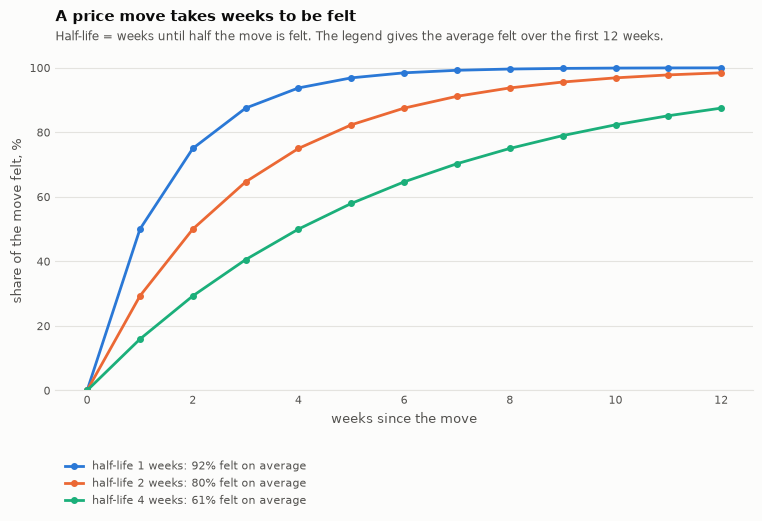

In [ ]:
# SETTINGS
HALF_LIVES = (1, 2, 4)             # weeks

fig = viz.phase_in(HALF_LIVES, horizon=12)
print(f"Half-life the model learned from this data: {fit.q('h')[1]:.1f} weeks "
      f"(80% range {fit.q('h')[0]:.1f} to {fit.q('h')[2]:.1f})")

## A3. The market benchmark: who we are compared with

**What it shows.** Each competitor's weight in the "soft cheapest rate" (r\*) that our price is
measured against, in one segment, in the latest week.

**Business meaning.** The cheapest lenders carry most of the weight, so *their* moves change our
price gap most. A move by a dear lender barely matters. Rates here are after your manual
adjustments (cashback and the like), which are the model's only view of competitor discounting.

**Maths (§2).** $r^* = -T \ln \sum_j e^{-r_j/T}$ with $T = 1/\beta$; lender $j$'s weight is
$e^{-r_j/T} / \sum_i e^{-r_i/T}$, which is also $\partial r^*/\partial r_j$.

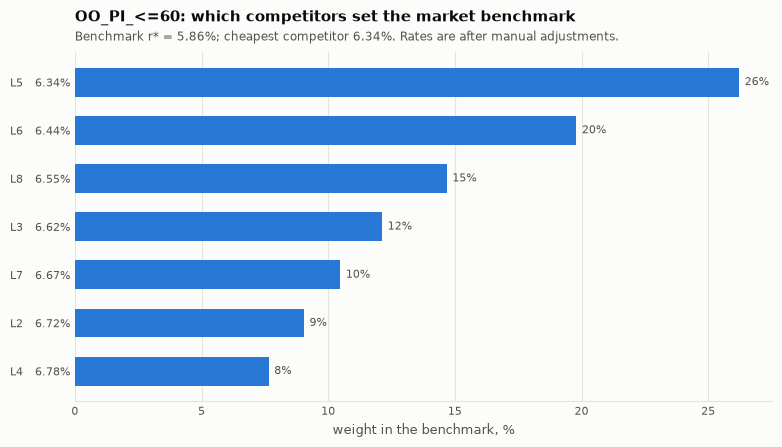

In [ ]:
fig = viz.benchmark_weights(fit, SEGMENT)

---
# Part B. What the model learned

## B1. Price sensitivity by segment

**What it shows.** Uplift per bp for every segment: the middle estimate and its 80% range. The
grey band is the range the model started from before seeing any data.

**How to read it.** A short bar well inside the grey band means the data pinned the figure down.
A bar nearly as wide as the band means the figure is still mostly judgment (see `prior_share` in
the table: near 0 = decided by data, near 1 = mostly the starting range).

**Business meaning.** This is where a basis point buys the most volume. On the sample data the
black ticks are the true values, so you can see how close the model gets.

**Maths (§5).** $\ln u_k = \mu_u + a_{\text{inv}}(\text{INV}-\tfrac12) + a_{\text{io}}
(\text{IO}-\tfrac12) + c_{\text{lvr}[k]}$: segments share evidence through purpose, repayment
type and LVR band, so a segment with no move of its own still gets an estimate.

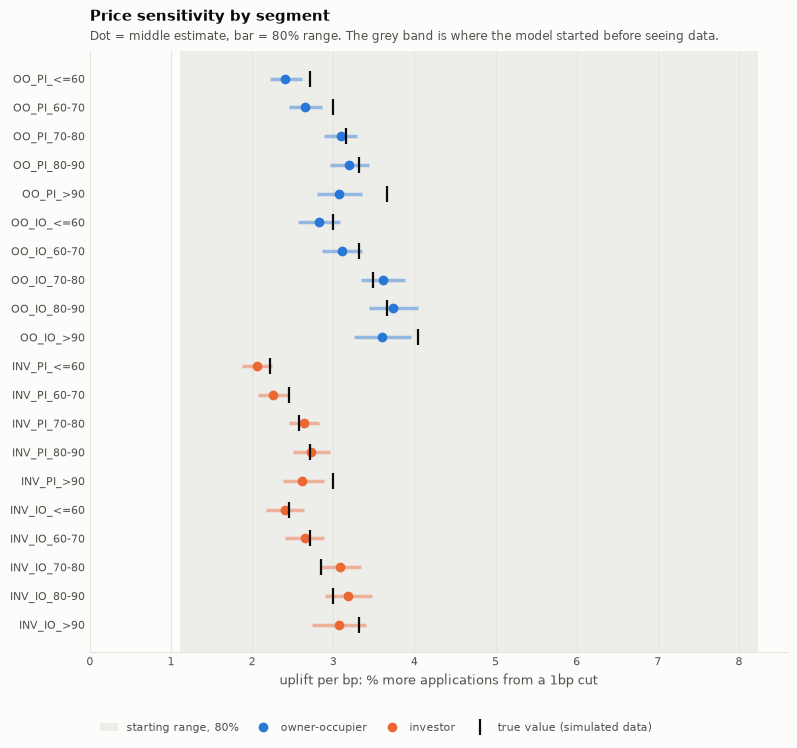

In [ ]:
fig = viz.sensitivity_by_segment(fit, truth)

In [ ]:
segments = report.segments_table(fit)
cols = ["segment", "lodg_us_per_week", "share_now_p50", "u_p10", "u_p50", "u_p90",
        "n_price_moves", "prior_share", "thin_volume"]
display(segments[cols].style.format({
    "lodg_us_per_week": "{:.0f}", "share_now_p50": "{:.1%}", "u_p10": "{:.2%}", "u_p50": "{:.2%}",
    "u_p90": "{:.2%}", "prior_share": "{:.2f}"}).hide(axis="index"))

segment,lodg_us_per_week,share_now_p50,u_p10,u_p50,u_p90,n_price_moves,prior_share,thin_volume
INV_IO_60-70,91,14.9%,2.41%,2.65%,2.89%,9,0.01,False
INV_IO_70-80,120,14.2%,2.84%,3.08%,3.34%,9,0.01,False
INV_IO_80-90,35,10.3%,2.90%,3.19%,3.48%,9,0.01,True
INV_IO_<=60,43,7.7%,2.17%,2.41%,2.64%,10,0.01,True
INV_IO_>90,10,11.1%,2.74%,3.07%,3.40%,10,0.01,True
INV_PI_60-70,56,4.4%,2.07%,2.26%,2.46%,10,0.01,False
INV_PI_70-80,183,12.4%,2.45%,2.64%,2.82%,10,0.00,False
INV_PI_80-90,34,3.6%,2.50%,2.72%,2.96%,10,0.01,True
INV_PI_<=60,112,10.9%,1.88%,2.06%,2.24%,10,0.01,False
INV_PI_>90,17,8.5%,2.38%,2.62%,2.88%,11,0.01,True


**The same figures as a grid**, to see the pattern across purpose, repayment type and LVR band
at a glance. Darker cells are more price-sensitive.

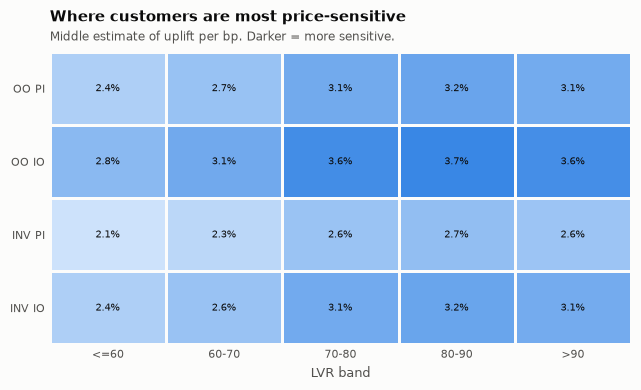

In [ ]:
fig = viz.sensitivity_grid(fit)

## B2. What the data added to the starting judgment

**What it shows.** The typical sensitivity across segments: the wide grey curve is the starting
range, the blue curve is what the model believes after the data. The orange line is a rule of
thumb to compare with.

**Business meaning.** If the blue curve is narrow and away from the rule of thumb, the data
disagree with the rule of thumb and say so with confidence. If the blue curve is nearly as wide
as the grey one, the data have added little and the answer is still judgment.

**Maths (§5, §6).** Prior $\mu_u \sim \mathcal N(\ln 0.03,\ 0.70^2)$; the blue curve is the
posterior of $e^{\mu_u}$ from the NUTS draws.

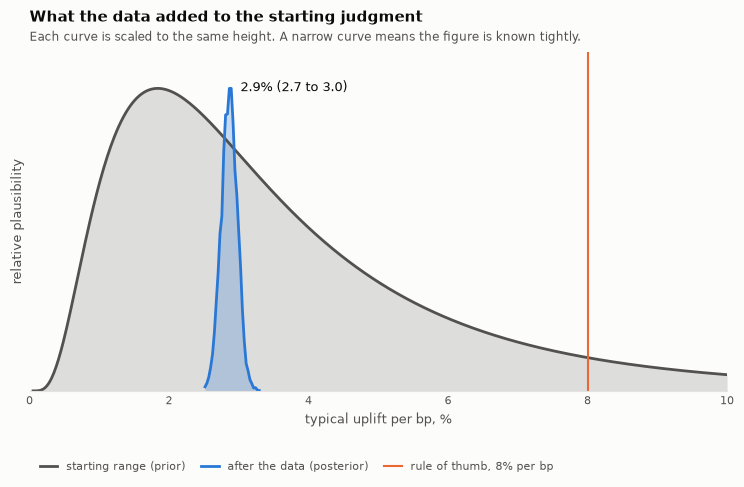

In [ ]:
# SETTINGS
RULE_OF_THUMB = 0.08               # fraction per bp; None to leave it off

fig = viz.prior_vs_posterior(fit, RULE_OF_THUMB)

## B3. Share history: how much of it was price

**What it shows.** *Top:* actual share (dots), the model's fit (blue), and **natural share**
(orange), the share we would have had if our price gap had stayed where it started. *Bottom:* the
price gap itself, as set (green steps) and as customers felt it (blue). Solid vertical lines are
our price moves; dashed lines are logged non-price changes such as campaigns or policy changes.

**How to read it.** Where blue sits above orange, price was winning us share; below, costing us
share. Movements in the orange line are everything that is *not* price: service, policy, brand,
season.

**Business meaning.** It separates "we lost share because we were dear" from "we lost share for
other reasons", which is the question behind most pricing reviews.

**Maths (§4).** $\operatorname{logit}\pi_{kt} = \underbrace{\alpha_k + g_t + v_{kt} + J_{kt}}_
{\text{natural level}} - \beta_k\,x_{kt}(h)$, with $g_t$ and $v_{kt}$ random walks and $J_{kt}$ a
level shift at each logged non-price change.

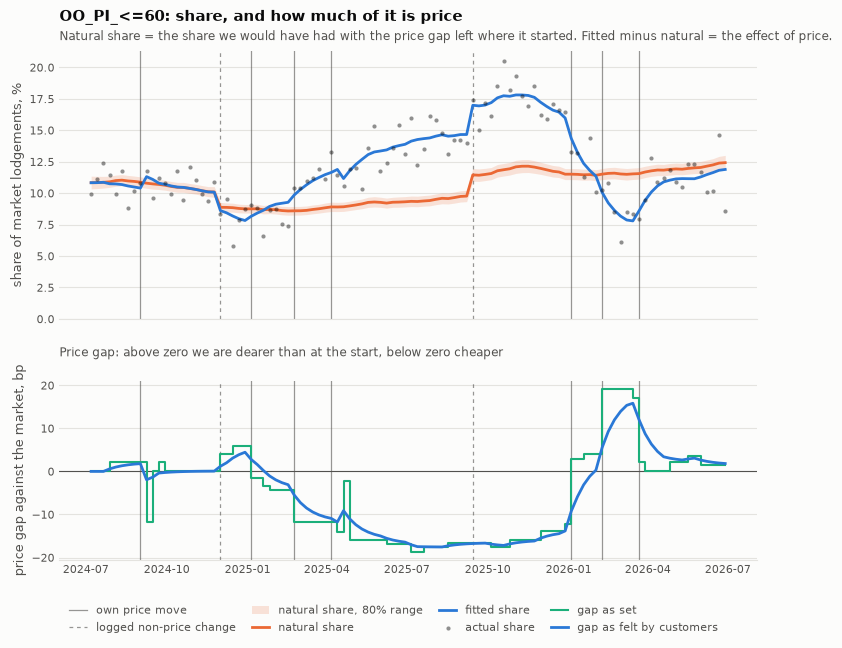

In [ ]:
# SETTINGS
HISTORY_SEGMENT = SEGMENT          # any segment name from the list printed in Setup

fig = viz.share_history(fit, HISTORY_SEGMENT)

---
# Part C. Scenarios

## C1. One scenario in detail

Set a price change and, optionally, competitor moves. The table gives the 12-week result in
applications and share; the charts show the week-by-week path.

**How to read the path chart.** The blue line is the middle estimate. The **dark band** is how
well we know the effect of price itself. The **light band** adds ordinary market movement and
weekly chance: it is what to hold the forecast against when the actuals come in. The orange line
is the long-run effect once the move is fully felt; the green line is the average over the 12
weeks, which is the figure for a quarterly plan.

**Maths (§7).** Each posterior draw is played forward with and without the change:
$\pi_\tau = \operatorname{expit}\!\big(\text{level}_T - \beta\,[x_T + (\text{gap}_T + \Delta
- x_T)(1-2^{-\tau/h})]\big)$. The full predictive range also simulates the random walks forward
and draws beta-binomial counts.

segment,range,"apps, no change","apps, with change",apps range,change,"share, no change","share, with change",share range
OO_PI_<=60,price effect only,"3,051","3,684","3,516 to 3,857",+21%,12.0%,14.4%,13.8 to 15.1%
OO_PI_<=60,with drift and noise,"3,051","3,677","3,417 to 3,966",+21%,12.0%,14.4%,13.4 to 15.5%


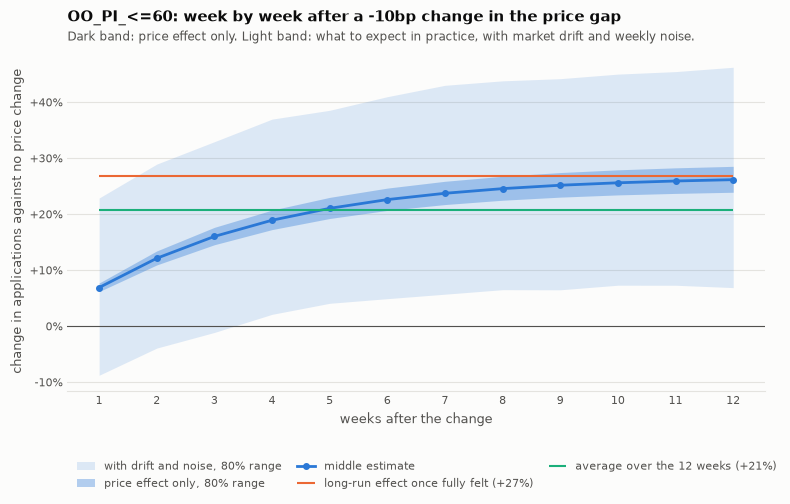

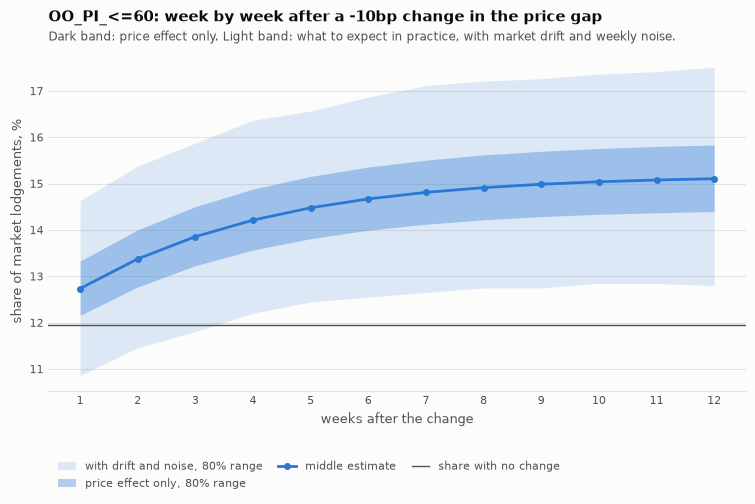

In [ ]:
# SETTINGS: the scenario
SCENARIO_SEGMENTS = [SEGMENT]      # one or more segment names, or "ALL"
HEADLINE_BPS = -10                 # change in our headline rate (negative = cut)
DISCRETIONARY_BPS = 0              # change in average discretionary discount (+ = less discount)
COMPETITOR_CHANGES = {}            # e.g. {"L5": -10} or {("OO_PI_70-80", "L5"): -10}; {} = none


def describe(fc):
    """A forecast as one plain table: applications and share, both ranges."""
    s = fc.summary
    lo, mid, hi = [c for c in s if c.startswith("apps_p")]
    slo, smid, shi = [c for c in s if c.startswith("share_pp_p")]
    return pd.DataFrame({
        "segment": s["segment"],
        "range": s["version"].map({"price_effect": "price effect only",
                                   "full_predictive": "with drift and noise"}),
        "apps, no change": s["baseline_apps_p50"].map("{:,.0f}".format),
        "apps, with change": s[mid].map("{:,.0f}".format),
        "apps range": s[lo].map("{:,.0f}".format) + " to " + s[hi].map("{:,.0f}".format),
        "change": (s[mid] / s["baseline_apps_p50"] - 1).map("{:+.0%}".format),
        "share, no change": s["baseline_share_pp_p50"].map("{:.1f}%".format),
        "share, with change": s[smid].map("{:.1f}%".format),
        "share range": s[slo].map("{:.1f}".format) + " to " + s[shi].map("{:.1f}%".format),
    })


fc = forecast.forecast(fit, SCENARIO_SEGMENTS, HEADLINE_BPS, DISCRETIONARY_BPS,
                       COMPETITOR_CHANGES or None)
display(describe(fc).style.hide(axis="index"))
fig = viz.forecast_path(fc)
fig = viz.forecast_path(fc, measure="share")

## C2. Several scenarios side by side

**What it shows.** Each row is a scenario you name. The dot is the middle estimate of
applications over 12 weeks; the thick bar is the price-effect range, the thin bar the range with
drift and noise. The vertical line is "no change".

**Business meaning.** Where two scenarios' thin bars overlap heavily, the model cannot tell them
apart in practice, however different the middle estimates look.

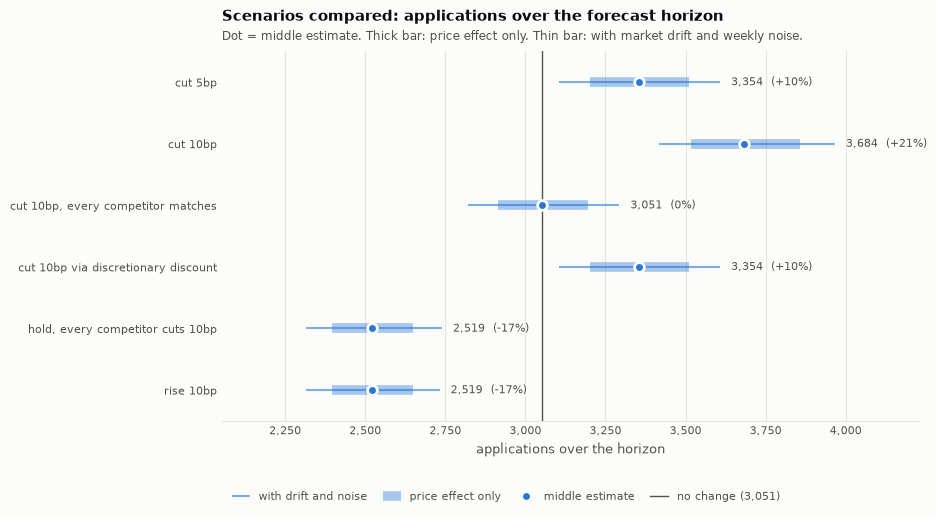

In [ ]:
# SETTINGS: name -> arguments of forecast.forecast (segments, headline bp, then optional extras)
lenders = sorted(prep.comp["lender"].unique()) if prep.comp is not None else []
SCENARIOS = {
    "cut 5bp": dict(d_headline_bps=-5),
    "cut 10bp": dict(d_headline_bps=-10),
    "cut 10bp, every competitor matches": dict(
        d_headline_bps=-10, competitor_changes={ln: -10 for ln in lenders}),
    "cut 10bp via discretionary discount": dict(d_headline_bps=0, d_discretionary_bps=-10),
    "hold, every competitor cuts 10bp": dict(
        d_headline_bps=0, competitor_changes={ln: -10 for ln in lenders}),
    "rise 10bp": dict(d_headline_bps=10),
}
COMPARE_SEGMENTS = [SEGMENT]       # or "ALL" for the whole book

compared = {name: forecast.forecast(fit, COMPARE_SEGMENTS, **kw) for name, kw in SCENARIOS.items()}
fig = viz.scenario_comparison(compared)

## C3. Every move size at once (1-D)

**What it shows.** The change in applications against the size of the move, for one segment. Blue
is the average over the next 12 weeks with its 80% range; orange is the long-run effect.

**Business meaning.** Read off any move size without rerunning anything. The range fans out as
moves get bigger: we know the effect of 5bp better than the effect of 25bp, because a bigger move
leans harder on the sensitivity estimate.

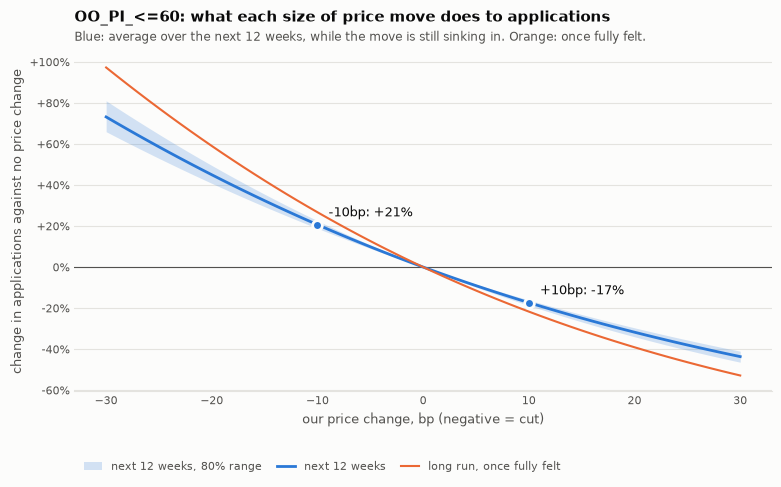

In [ ]:
# SETTINGS
CURVE_SEGMENT = SEGMENT
MOVES = np.arange(-30, 31, 1)      # bp

fig = viz.move_size_curve(fit, CURVE_SEGMENT, MOVES)

## C4. Every segment against every move size (2-D)

**What it shows.** One row per segment, one column per move size. First as a % change in
applications, then as a number of applications over 12 weeks. Blue is a gain, red a loss.

**Business meaning.** The % view shows where customers are most responsive. The count view shows
where the volume is: a very responsive but small segment may add fewer applications than a
less responsive large one.

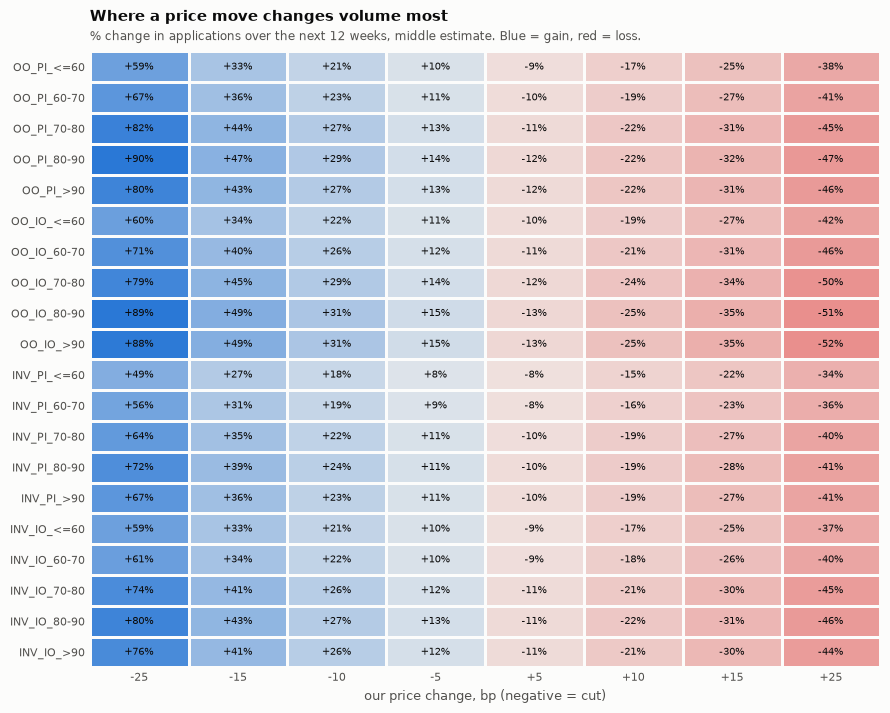

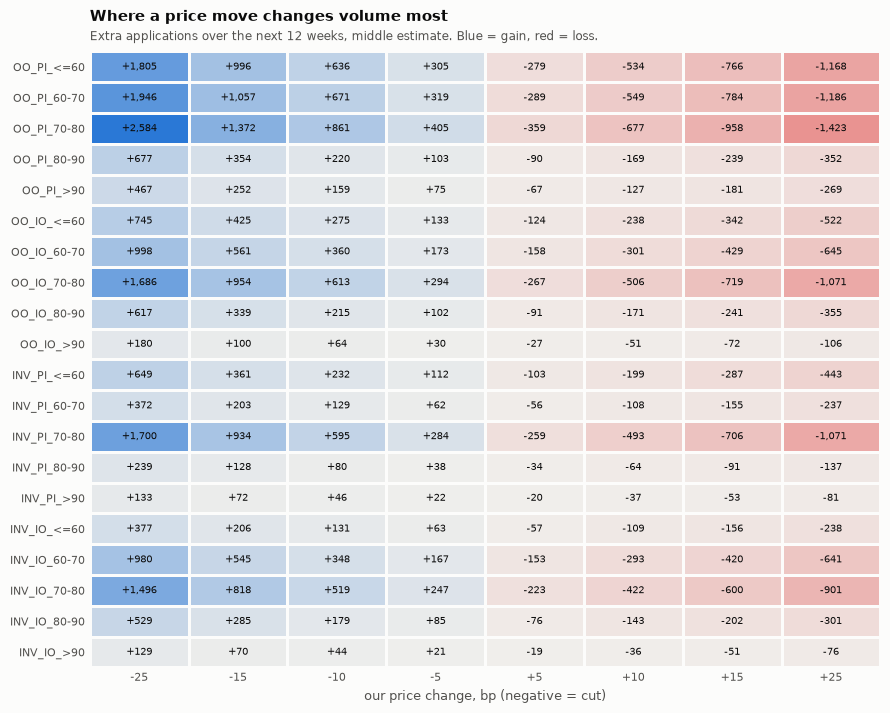

In [ ]:
# SETTINGS
GRID_MOVES = (-25, -15, -10, -5, 5, 10, 15, 25)

fig = viz.segment_move_heatmap(fit, GRID_MOVES, measure="pct")
fig = viz.segment_move_heatmap(fit, GRID_MOVES, measure="apps")

## C5. Our move against a competitor's move (2-D and 3-D)

**What it shows.** Across: our price change. Down: a competitor's price change. Each cell is the
middle estimate of the change in our applications over 12 weeks. The same numbers follow as a 3-D
surface.

**How to read it.** The row at 0 is "no competitor response". Moving up or down a column shows how
much of our move a competitor's reaction takes back. Grey cells are where the two moves cancel.

**Business meaning.** A cut that the cheapest lender matches is worth much less than the headline
figure. Set `WHO = "all"` to see the whole market matching: then only the *difference* between
our move and theirs matters.

**Maths (§2, §7).** The competitor's move shifts the benchmark by $\Delta r^*$ (through the
soft-min, so roughly its weight times its move), and the gap changes by
$\Delta = \Delta_{\text{ours}} - \Delta r^*$.

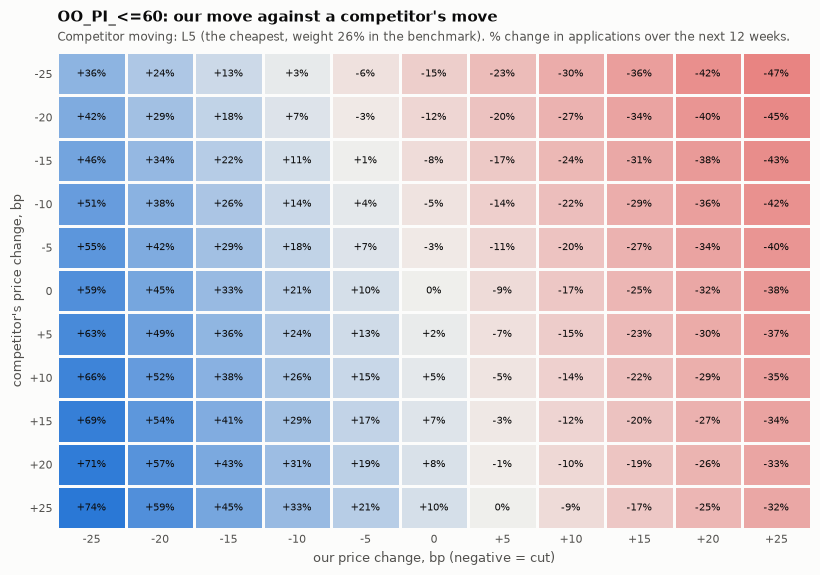

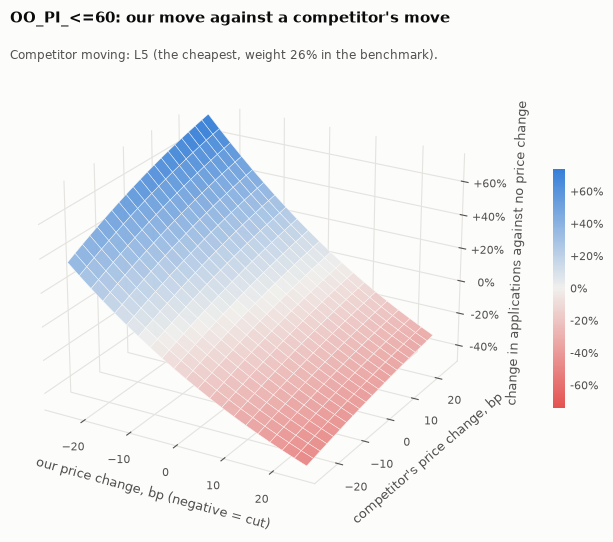

In [ ]:
# SETTINGS
COMP_SEGMENT = SEGMENT
WHO = "cheapest"                   # "cheapest", "all", or a lender name such as "L5"
ELEV, AZIM = 24, -60               # 3-D viewing angle: height above the surface, rotation

if prep.comp is None:
    print("This model was fitted without competitor rates: no competitor scenarios.")
else:
    fig = viz.competitor_response(fit, COMP_SEGMENT, WHO)
    fig = viz.competitor_response(fit, COMP_SEGMENT, WHO, view="3d", elev=ELEV, azim=AZIM)

## C6. Move size against time (3-D)

**What it shows.** The effect on each week's applications, across move size (one axis) and weeks
since the move (the other). It joins the response curve of A1 to the delay of A2.

**How to read it.** Follow the surface away from week 1: it rises (for a cut) as the move is felt,
then flattens. Slice it at one move size and you get the path chart of C1; slice it at week 12
and you get close to the long-run curve of C3. Change `ELEV` and `AZIM` to turn it.

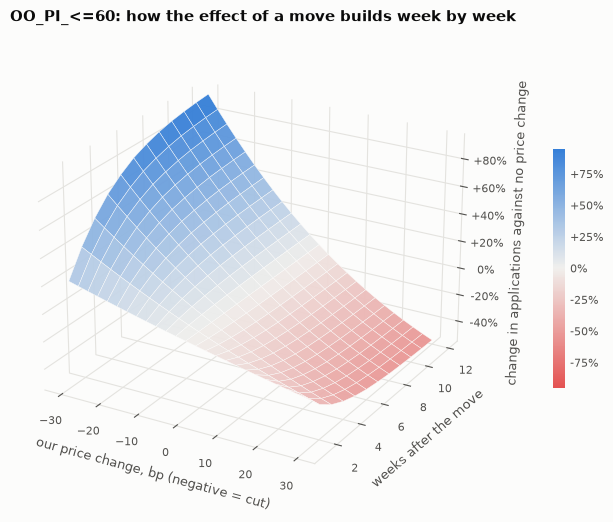

In [ ]:
# SETTINGS
SURFACE_SEGMENT = SEGMENT
ELEV, AZIM = 24, -60

fig = viz.phase_in_surface(fit, SURFACE_SEGMENT, elev=ELEV, azim=AZIM)

## C7. Volume against margin (illustration)

**This chart goes beyond the model.** The model forecasts volume only. Here the volume forecast is
multiplied by a margin that **you** supply, to show where the two pull against each other:

> income on new lending = applications × (margin today + price change)

**How to read it.** Blue is volume. Orange is income on new lending. Where orange peaks is the
move that maximises income on new lending over the next 12 weeks, on these assumptions.

**What it leaves out.** Any cost of the same rate change on existing customers, funding and
capital costs, conversion and loan size differences, and anything beyond 12 weeks. Treat it as a
way to frame the trade-off, not as an answer.

**Maths.** With volume multiplier $m(\Delta)$ and margin $\mu$, relative income is
$m(\Delta)(\mu+\Delta)/\mu$. At the margin a cut pays when $u > 1/\mu$: at 3% per bp, whenever
the margin is above about 33bp.

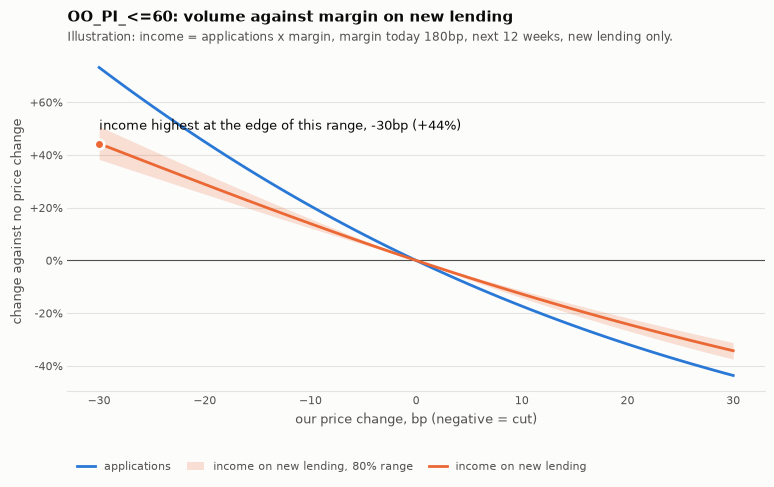

In [ ]:
# SETTINGS
MARGIN_SEGMENT = SEGMENT
MARGIN_BPS = 180                   # YOUR figure: margin earned on new lending today, bp

fig = viz.margin_tradeoff(fit, MARGIN_SEGMENT, MARGIN_BPS)

## C8. Interactive explorer

Drag the sliders to rerun the forecast. (Needs `ipywidgets`, which `uv sync` installs; works in
VS Code and Jupyter.)

In [ ]:
try:
    import ipywidgets as w
except ImportError:
    w = None
    print("ipywidgets is not installed: run `uv sync`, or use the SETTINGS cells above.")

if w is not None:
    import matplotlib.pyplot as plt

    slider = dict(min=-30, max=30, step=1, continuous_update=False,
                  style={"description_width": "190px"}, layout=w.Layout(width="520px"))

    @w.interact(
        segment=w.Dropdown(options=prep.segs, value=SEGMENT, description="Segment"),
        ours=w.IntSlider(value=-10, description="Our headline change, bp", **slider),
        theirs=w.IntSlider(value=0, description="Every competitor's change, bp", **slider),
        measure=w.ToggleButtons(options=[("applications", "apps"), ("share", "share")],
                                description="Show"))
    def explore(segment, ours, theirs, measure):
        changes = {ln: theirs for ln in lenders} if theirs and lenders else None
        f = forecast.forecast(fit, segment, ours, competitor_changes=changes)
        display(describe(f).style.hide(axis="index"))
        viz.forecast_path(f, measure=measure)
        plt.show()

---
# Part D. How far to trust it

## D1. The raw history, with no model

**What it shows.** For each past price move: what weekly applications did afterwards (black dot),
beside what they *should* have done at two assumed sensitivities (coloured ticks).

**Business meaning.** Look at this first. It needs no model and no trust in one. If the dots
sit near the 3% ticks and far from the 8% ticks, the raw history itself says which sensitivity is
in the right region. It is rough: nothing here allows for other things changing at the same time.

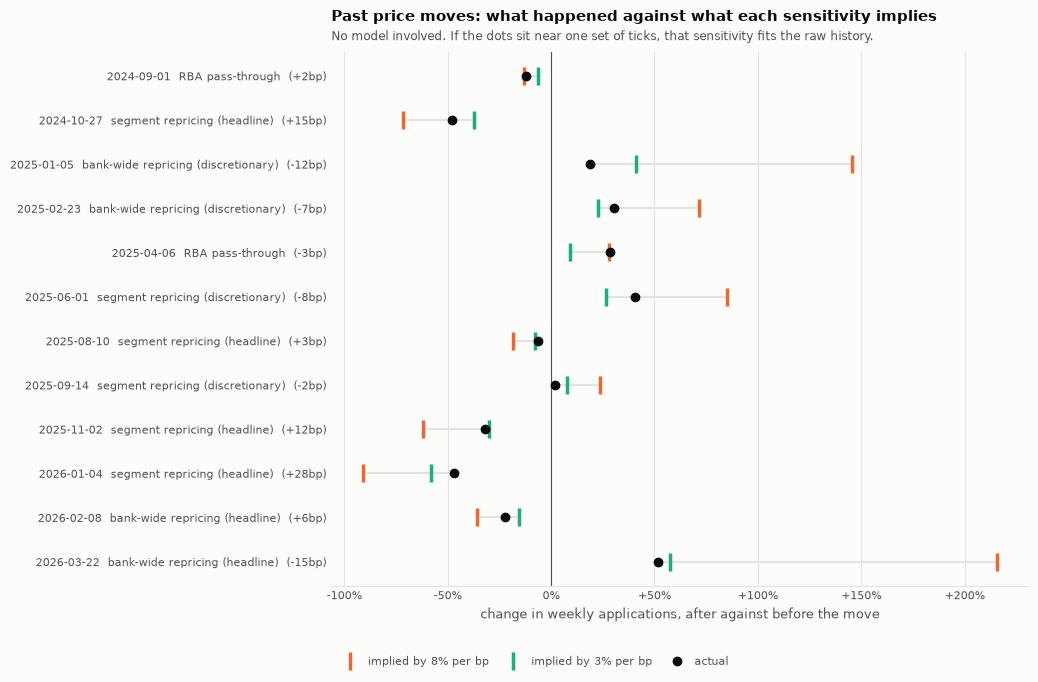

In [ ]:
def table(name):
    """A csv from the same run as the fit, or None with a note on how to produce it."""
    path = OUT / name
    if path.exists():
        return pd.read_csv(path)
    print(f"{path} not found; see the README for the command that writes it.")


check = table("check_moves.csv")
if check is not None:
    fig = viz.raw_moves(check)

## D2. Backtests: forecasts against what happened

**What it shows.** *First chart:* for each past price move, the model was refitted with the
following 12 weeks hidden, then asked to forecast them. The bar is its 80% range, the diamond is
what happened. *Second chart:* the same for quiet periods with no price move, which shows the
error that remains even when price does nothing.

**How to read it.** About four diamonds in five should sit inside their bar. Many more outside
means the ranges are too narrow; all inside with room to spare means they are too wide.

**Business meaning.** This is the evidence that the stated ranges can be taken at face value.

These tables come from `uv run elasticity validate events` and `validate quiet` (several refits,
so they are run once from the command line, not here).

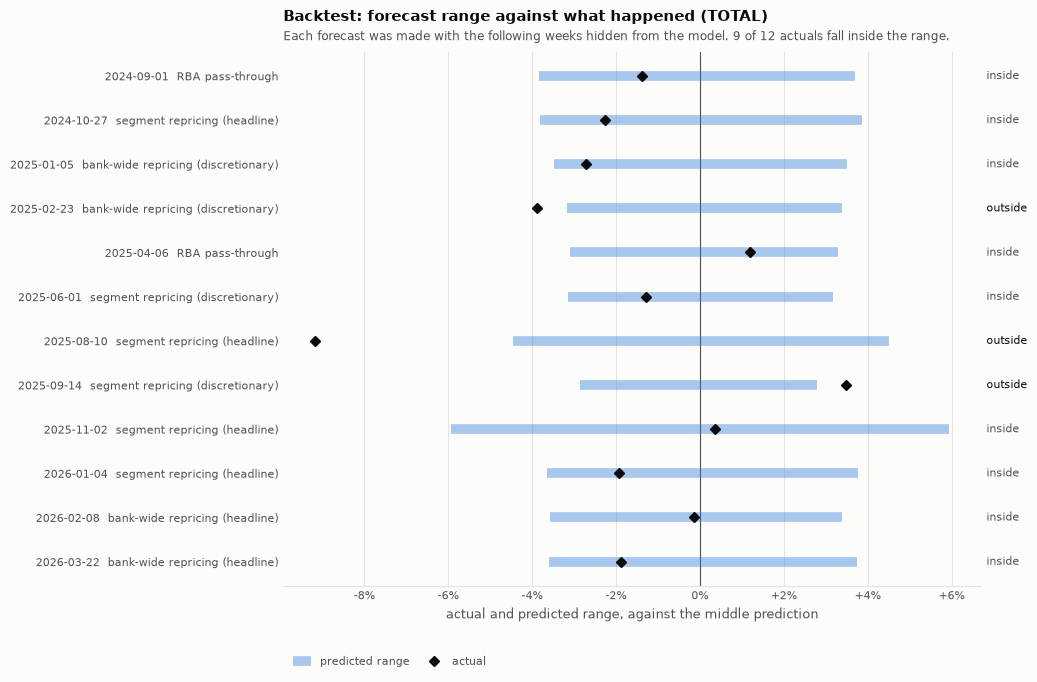

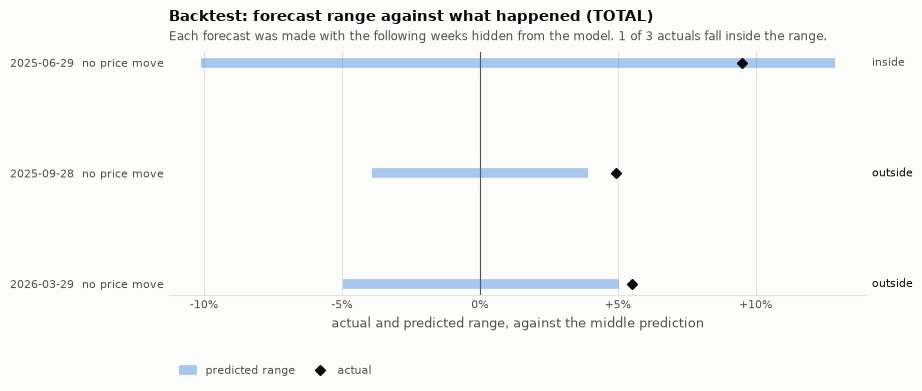

In [ ]:
for name in ("validate_events.csv", "validate_quiet.csv"):
    t = table(name)
    if t is not None:
        fig = viz.backtest(t)

## D3. How precise the forecast can be

**What it shows.** *First chart:* the half-width of the 80% range of 12-week applications, by
group and move size, including market drift and weekly noise. A tick marks cells inside the ±5%
target. *Second chart:* each segment's precision against its weekly volume.

**Business meaning.** Precision is best for small moves in large groups. Thin segments (few
lodgements a week) are noisy whatever the model does, which is why they should be read in groups.
The gap between blue and orange dots in the second chart is the part no pricing model controls.

**Maths (§8).** Three terms add: posterior uncertainty in $\beta$ (grows with $|\Delta|$),
random-walk drift in the natural level over the horizon, and beta-binomial count noise (roughly
$\propto 1/\sqrt{\text{lodgements}}$).

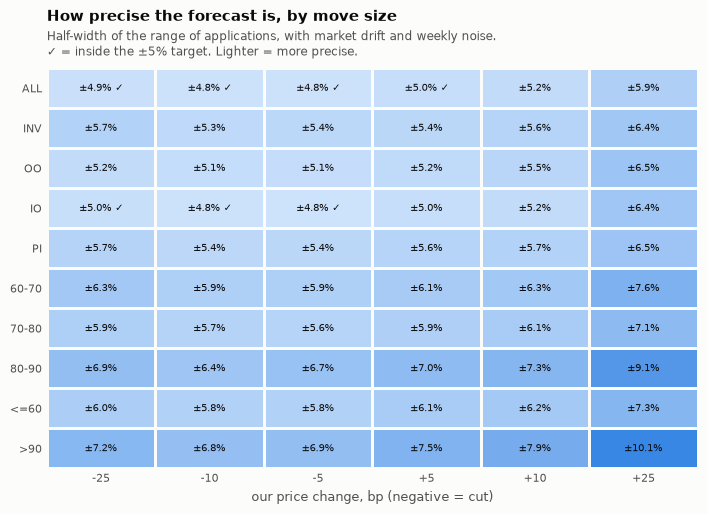

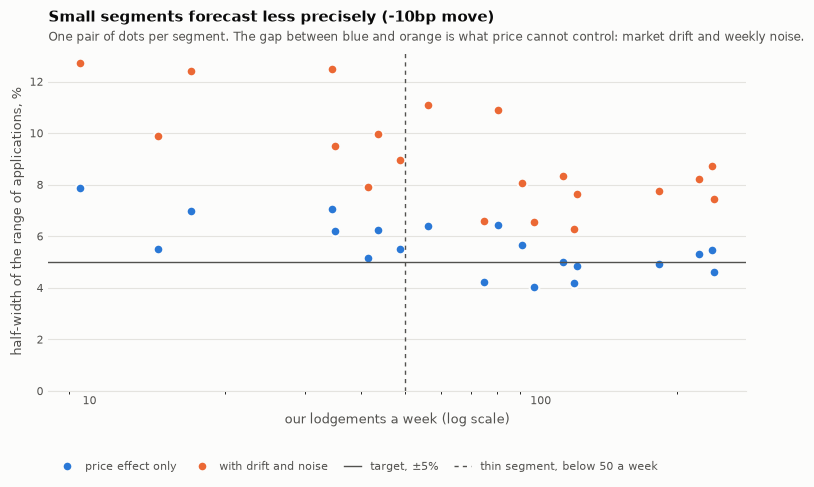

In [ ]:
# SETTINGS
ACCURACY_MOVE = -10                # bp; one of the moves in the accuracy table

accuracy = forecast.accuracy_table(fit)
fig = viz.accuracy_heatmap(accuracy, "groups", target=fit.cfg.target_apps_rel)
fig = viz.uncertainty_vs_volume(fit, accuracy, ACCURACY_MOVE)

**The same precision table segment by segment** (change `version` to `"price_effect"` to see the
part that is down to the sensitivity estimate alone):

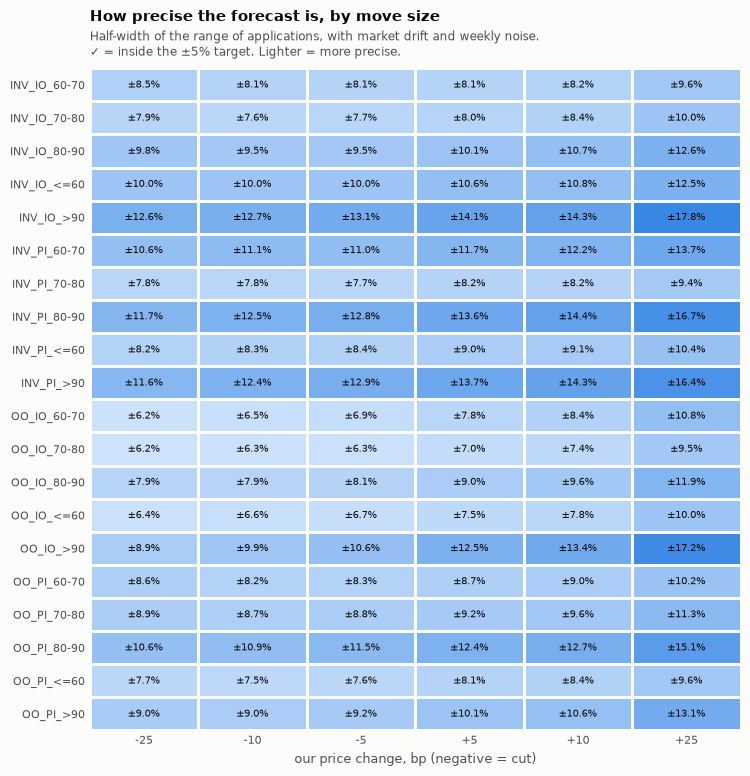

In [ ]:
fig = viz.accuracy_heatmap(accuracy, "segment", version="full_predictive",
                           target=fit.cfg.target_apps_rel)

## D4. Does the answer depend on our judgment calls?

**What it shows.** The typical sensitivity when the model is refitted with one judgment changed at
a time: the centre of the starting range (2, 4, 8% per bp), a softer or harder benchmark (T),
discretionary discounts counted at 30% or 70% (kappa), and two structural alternatives.

**Business meaning.** Rows that sit on the blue line show that the judgment does not drive the
answer. A row that moves away is a judgment worth debating, and its distance is how much it
matters. From `uv run elasticity sensitivity`.

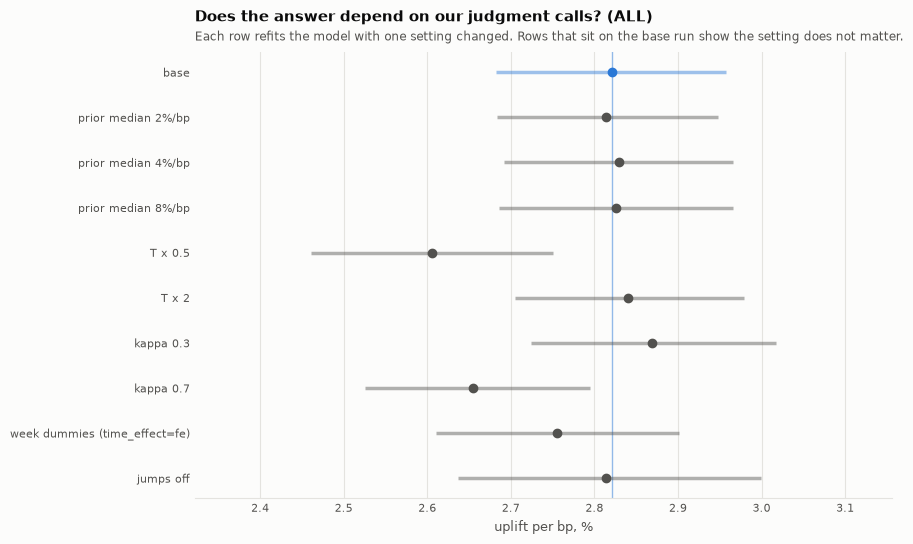

In [ ]:
sens = table("sensitivity.csv")
if sens is not None:
    fig = viz.sensitivity_runs(sens, name="ALL")   # or a group: "OO", "INV", "PI", "IO", an LVR band

---
# Part E. Save every chart

Writes the full set as PNG files for a pack. The same thing from the command line:

```
uv run elasticity charts --fit outputs/sample/fit.pkl --out outputs/sample/charts
```

## Limits to keep in mind

- The estimates rest on a small number of price moves. Where `prior_share` is high, the figure is
  mostly judgment.
- "No competitor response and no market movement" is never observed; the price-effect range
  answers a what-if, the range with drift and noise is the one to check against actuals.
- Competitor discounts we cannot see make customers look less price-sensitive than they are.
- The full list is in [`docs/overview.md`](../docs/overview.md), step 9.

In [ ]:
# SETTINGS
CHART_DIR = OUT / "charts"

written = viz.gallery(fit, CHART_DIR, segment=SEGMENT, move_bps=-10, margin_bps=MARGIN_BPS,
                      outputs=OUT, truth=ROOT / TRUTH_PATH if TRUTH_PATH else None)
print(f"Wrote {len(written)} charts to {CHART_DIR}")

Wrote 24 charts to /Users/andrewmacleod/workspace/price-elasticity/outputs/sample/charts
